# 06 Robustness checks

*Part of **Step 6 (Experiments)**: checking the main finding from notebook 04 doesn't depend on choices made along the way.*

The main finding is that, later in a chase, teams on DLS par with more wickets in hand win more often than teams with fewer. The cleanest version of it is the gap in the **last 5 overs** between teams 3-5 down and teams 6-9 down.

That result came from a few judgement calls: "on par" meaning within 2 runs, combining T20Is and the IPL, and using every season. If the gap disappears when any of those change, it wasn't a real finding. So this notebook reruns it under each alternative, and also looks at the 149 real DLS-affected matches.

## Setup

Same style and par calculation as notebook 05.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# one consistent style for every figure
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2,
})
os.makedirs("figures", exist_ok=True)

# rebuild the par score at every ball (same method as notebook 04)
table = pd.read_csv("reference/dls_standard_edition.csv").sort_values("overs_left")

def resources_left(balls_left, wickets):
    overs_left = np.asarray(balls_left) / 6
    wickets = np.asarray(wickets)
    out = np.zeros(len(overs_left))
    for w in range(10):
        m = wickets == w
        out[m] = np.interp(overs_left[m], table["overs_left"], table[f"w{w}"])
    return out

R1 = resources_left([120], [0])[0]

df = pd.read_csv("data/chases.csv")
df["year"] = pd.to_datetime(df["date"]).dt.year
df["par"] = (df["target"] - 1) * (R1 - resources_left(df["balls_left"], df["wickets"])) / R1
df["margin"] = df["runs"] - df["par"]

normal = df[~df["dls"]]
normal = normal[normal.groupby("match_id")["balls_left"].transform("max") >= 119]
s = normal[(normal["balls_left"] <= 90) & (normal["balls_left"] > 0) & (normal["wickets"] < 10)]
print(normal["match_id"].nunique(), "full chases")


4493 full chases


In [2]:
def last5_gap(data, tol=2):
    """Win rate at par in the last 5 overs: 3-5 down vs 6-9 down, and the gap with a 95% interval."""
    on_par = (data[data["margin"].abs() <= tol]
              .sort_values("balls_left", ascending=False)
              .drop_duplicates(["match_id", "wickets"]))
    late = on_par[on_par["balls_left"] <= 30]
    a = late[late["wickets"].between(3, 5)]["won"]
    b = late[late["wickets"].between(6, 9)]["won"]
    gap = a.mean() - b.mean()
    se = np.sqrt(a.mean() * (1 - a.mean()) / len(a) + b.mean() * (1 - b.mean()) / len(b))
    return {"3-5 down": a.mean(), "6-9 down": b.mean(), "gap": gap,
            "low": gap - 1.96 * se, "high": gap + 1.96 * se, "n": len(a) + len(b)}

## Rerunning under different choices

Each row changes one thing from the main analysis:
- **Par window:** within 1 or 3 runs instead of 2
- **Competition:** T20Is and IPL separately
- **Era:** up to 2018 vs 2019 onwards, since T20 scoring has risen sharply

If the gap stays clearly above 0 in every row, the finding is robust.

In [3]:
checks = {
    "Main analysis (within 2 runs)": last5_gap(s),
    "Within 1 run": last5_gap(s, tol=1),
    "Within 3 runs": last5_gap(s, tol=3),
    "T20Is only": last5_gap(s[s["comp"] == "t20i"]),
    "IPL only": last5_gap(s[s["comp"] == "ipl"]),
    "Up to 2018": last5_gap(s[s["year"] <= 2018]),
    "2019 onwards": last5_gap(s[s["year"] >= 2019]),
}
robust = (pd.DataFrame(checks).T * [100, 100, 100, 100, 100, 1]).round(1)
robust["n"] = robust["n"].astype(int)
robust

,3-5 down,6-9 down,gap,low,high,n
Main analysis (within 2 runs),60.4,46.8,13.6,8.5,18.7,1444
Within 1 run,60.8,45.8,14.9,8.9,20.9,1046
Within 3 runs,60.8,44.8,16.0,11.4,20.6,1747
T20Is only,59.9,44.7,15.2,8.8,21.6,923
IPL only,61.0,52.3,8.7,-0.0,17.5,521
Up to 2018,62.3,50.5,11.8,3.2,20.5,523
2019 onwards,58.9,45.2,13.7,7.3,20.1,921


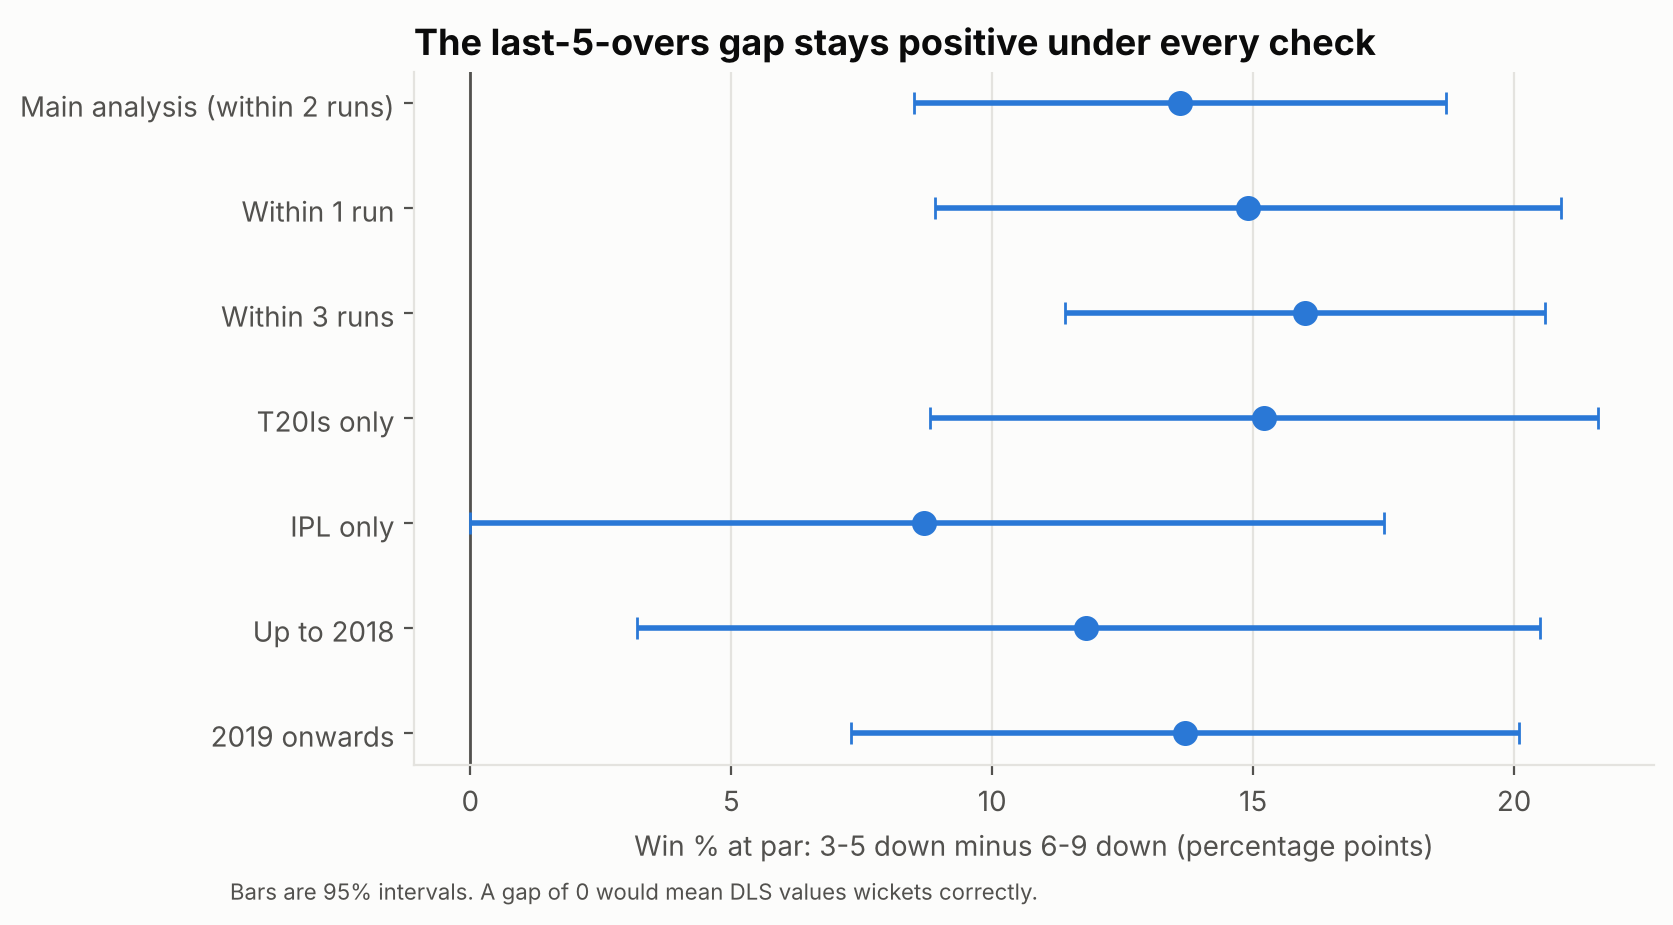

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
rows = robust.iloc[::-1]
y = np.arange(len(rows))
ax.axvline(0, color=MUTED, lw=1)
ax.errorbar(rows["gap"], y, xerr=[rows["gap"] - rows["low"], rows["high"] - rows["gap"]],
            fmt="o", color=BLUE, ms=8, capsize=4)
ax.set_yticks(y, rows.index)
ax.set_xlabel("Win % at par: 3-5 down minus 6-9 down (percentage points)")
ax.set_title("The last-5-overs gap stays positive under every check")
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.04, "Bars are 95% intervals. A gap of 0 would mean DLS values wickets correctly.",
         color=MUTED, fontsize=8)
plt.savefig("figures/robustness.png", dpi=200, bbox_inches="tight")
plt.show()

## The 149 real DLS matches

A direct look at matches where DLS was actually used. Chasing teams win about 52% of normal matches, so a fair system should give something similar here. With only 149 matches the margin of error is large (about ±8 points), so this can only catch a big bias.

In [5]:
dls = df[df["dls"]].drop_duplicates("match_id")
p, n = dls["won"].mean(), len(dls)
ci = 1.96 * np.sqrt(p * (1 - p) / n)
print(f"Chasing team won {p*100:.1f}% of {n} DLS matches (95% interval {100*(p-ci):.1f}-{100*(p+ci):.1f}%)")
dls.groupby("comp")["won"].agg(matches="count", win_rate="mean").round(3)

Chasing team won 51.7% of 149 DLS matches (95% interval 43.7-59.7%)


,matches,win_rate
comp,,
ipl,23,0.696
t20i,126,0.484


## Results

- **The last-5-overs gap holds up under every check.** Teams on par with 3-5 wickets down beat teams 6-9 down by roughly 9-16 percentage points whichever par window, competition or era is used. Its interval stays above 0 everywhere except the IPL alone, where the gap is smaller (about 9 points) and the interval only just reaches 0 because there are fewer matches.
- **It isn't a recent or an older effect.** It shows up both before and after 2019, even though scoring rates have changed a lot.
- **The real DLS matches don't show a large overall bias.** Chasing teams won 51.7% of the 149 DLS-affected matches, close to the normal 52%. That fits notebook 04: on average DLS is fair, and the problem is in how it values wickets, which a simple win rate across all DLS games can't detect. (The IPL figure, 70% from only 23 matches, is too small a sample to mean anything.)

**Conclusion:** the finding from notebook 04 is not an artefact of the analysis choices.